In [11]:
import math
import numpy as np
import matplotlib.pyplot as plt

SEED = 12345
N_PER_CLASS = 1000
K = 3                                   # three Gaussian components per class

# mixture weights and means for the two classes
PI = {0: [0.40, 0.35, 0.25],
      1: [0.30, 0.40, 0.30]}
MU = {0: [[-4, -2], [0, 3], [4, -1]],
      1: [[-3, 3], [1, -3], [5, 3]]}

# covariance matrices C_i (one per component, same for both classes)
C = {
    "spherical": [[[1, 0], [0, 1]], [[1, 0], [0, 1]], [[1, 0], [0, 1]]],
    "diagonal":  [[[2, 0], [0, 0.5]], [[0.5, 0], [0, 2]], [[1.5, 0], [0, 0.7]]],
    "full":      [[[2, 0.8], [0.8, 1]], [[1.5, -0.6], [-0.6, 1]], [[1, 0.5], [0.5, 1.5]]],
}


In [13]:
# CELL 3: Box-Muller -> two standard normal values
def box_muller(rng):
    u1 = rng.uniform()
    u2 = rng.uniform()
    r = math.sqrt(-2 * math.log(u1))
    return r * math.cos(2 * math.pi * u2), r * math.sin(2 * math.pi * u2)

print(box_muller(LCG(SEED)))

(2.7749468423937507, 0.2895642870200742)


In [14]:
# CELL 4: generate data
# For C = [[a, b], [b, c]]:  x = mu + L z  with  L = [[sqrt(a), 0], [b/sqrt(a), sqrt(c - b*b/a)]]
# (written by hand, no np.linalg.cholesky)

def generate_point(mean, cov, rng):
    z1, z2 = box_muller(rng)
    a, b, c = cov[0][0], cov[0][1], cov[1][1]
    x = mean[0] + math.sqrt(a) * z1
    y = mean[1] + (b / math.sqrt(a)) * z1 + math.sqrt(c - b * b / a) * z2
    return [x, y]

def generate_class(cls, case, rng):
    points = []
    for n in range(N_PER_CLASS):
        u = rng.uniform()
        if u < PI[cls][0]:                           # mixture-weight ranges
            i = 0
        elif u < PI[cls][0] + PI[cls][1]:
            i = 1
        else:
            i = 2
        points.append(generate_point(MU[cls][i], C[case][i], rng))
    return np.array(points)

DATA = {}                       # DATA[case][class] = array of points
for case in C:
    rng = LCG(SEED)
    DATA[case] = {0: generate_class(0, case, rng),
                  1: generate_class(1, case, rng)}
    print(case, DATA[case][0].shape, DATA[case][1].shape)

spherical (1000, 2) (1000, 2)
diagonal (1000, 2) (1000, 2)
full (1000, 2) (1000, 2)


In [4]:


def generate_point(mean, cov, rng):
    z1, z2 = box_muller(rng)
    a, b, c = cov[0][0], cov[0][1], cov[1][1]
    x = mean[0] + math.sqrt(a) * z1
    y = mean[1] + (b / math.sqrt(a)) * z1 + math.sqrt(c - b * b / a) * z2
    return np.array([x, y])

def generate_class(cls, case, rng):
    X = np.zeros((N_PER_CLASS, 2))
    comp = np.zeros(N_PER_CLASS, dtype=int)
    for n in range(N_PER_CLASS):
        u = rng.uniform()
        if u < PI[cls][0]:                          # weight ranges
            i = 0
        elif u < PI[cls][0] + PI[cls][1]:
            i = 1
        else:
            i = 2
        X[n] = generate_point(MU[cls][i], C[case][i], rng)
        comp[n] = i
    return X, comp

DATA = {}                      # DATA[case][class] = (points, component labels)
for case in C:
    rng = LCG(SEED)
    DATA[case] = {c: generate_class(c, case, rng) for c in (0, 1)}
    print(case, DATA[case][0][0].shape, DATA[case][1][0].shape)

spherical (1000, 2) (1000, 2)
diagonal (1000, 2) (1000, 2)
full (1000, 2) (1000, 2)


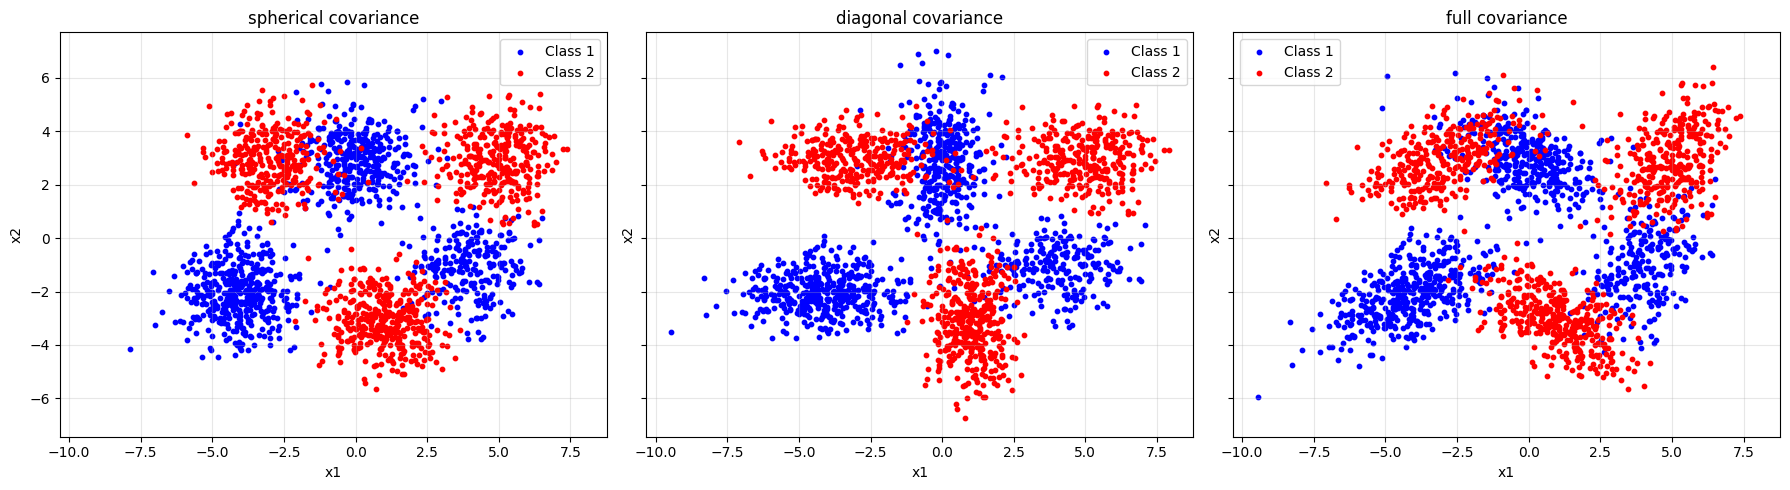

In [15]:
# CELL 5: plot generated data (two classes, different colours, all three covariance types)
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
for ax, case in zip(axes, DATA):
    ax.scatter(DATA[case][0][:, 0], DATA[case][0][:, 1], s=10, c="blue", label="Class 1")
    ax.scatter(DATA[case][1][:, 0], DATA[case][1][:, 1], s=10, c="red", label="Class 2")
    ax.set_title(case + " covariance")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
# CELL 6: 80/20 split per class (data is already in random order)
n_train = int(0.8 * N_PER_CLASS)

TRAIN = {}                      # TRAIN[case][class] = training points
TEST = {}                       # TEST[case][class] = test points
for case in DATA:
    TRAIN[case] = {c: DATA[case][c][:n_train] for c in (0, 1)}
    TEST[case] = {c: DATA[case][c][n_train:] for c in (0, 1)}
    print(case, "train:", TRAIN[case][0].shape, "test:", TEST[case][0].shape)

spherical train: (800, 2) test: (200, 2)
diagonal train: (800, 2) test: (200, 2)
full train: (800, 2) test: (200, 2)


In [17]:
# CELL 7: K-means
# repeat: assign each point to the nearest centroid, move each centroid to the mean of its points
def kmeans(X, K, max_iter=100):
    centroids = X[:K].copy()                 # start at the first K training points
    for _ in range(max_iter):
        d = ((X[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2)   # squared distances
        labels = d.argmin(axis=1)
        new_centroids = centroids.copy()
        for k in range(K):
            if np.any(labels == k):
                new_centroids[k] = X[labels == k].mean(axis=0)
        if np.allclose(new_centroids, centroids):                        # stopped changing
            break
        centroids = new_centroids
    return centroids, labels

In [18]:
# CELL 8: run K-means on the training data of each class
CENTROIDS = {}                  # CENTROIDS[case][class] = K centroids
LABELS = {}                     # LABELS[case][class] = cluster of each training point
for case in TRAIN:
    CENTROIDS[case] = {}
    LABELS[case] = {}
    for c in (0, 1):
        CENTROIDS[case][c], LABELS[case][c] = kmeans(TRAIN[case][c], K)
    print(case)
    for c in (0, 1):
        print("  class", c, "centroids:", np.round(CENTROIDS[case][c], 2).tolist())
        print("  class", c, "designed means:", MU[c])

spherical
  class 0 centroids: [[-4.12, -2.0], [4.0, -1.04], [-0.03, 2.89]]
  class 0 designed means: [[-4, -2], [0, 3], [4, -1]]
  class 1 centroids: [[0.96, -3.09], [4.94, 2.9], [-2.99, 2.93]]
  class 1 designed means: [[-3, 3], [1, -3], [5, 3]]
diagonal
  class 0 centroids: [[-4.16, -1.99], [-0.02, 2.85], [4.0, -1.03]]
  class 0 designed means: [[-4, -2], [0, 3], [4, -1]]
  class 1 centroids: [[0.97, -3.12], [4.91, 2.91], [-3.02, 2.95]]
  class 1 designed means: [[-3, 3], [1, -3], [5, 3]]
full
  class 0 centroids: [[-4.21, -2.09], [3.97, -0.98], [-0.11, 2.91]]
  class 0 designed means: [[-4, -2], [0, 3], [4, -1]]
  class 1 centroids: [[0.95, -3.05], [4.93, 2.88], [-3.02, 2.94]]
  class 1 designed means: [[-3, 3], [1, -3], [5, 3]]


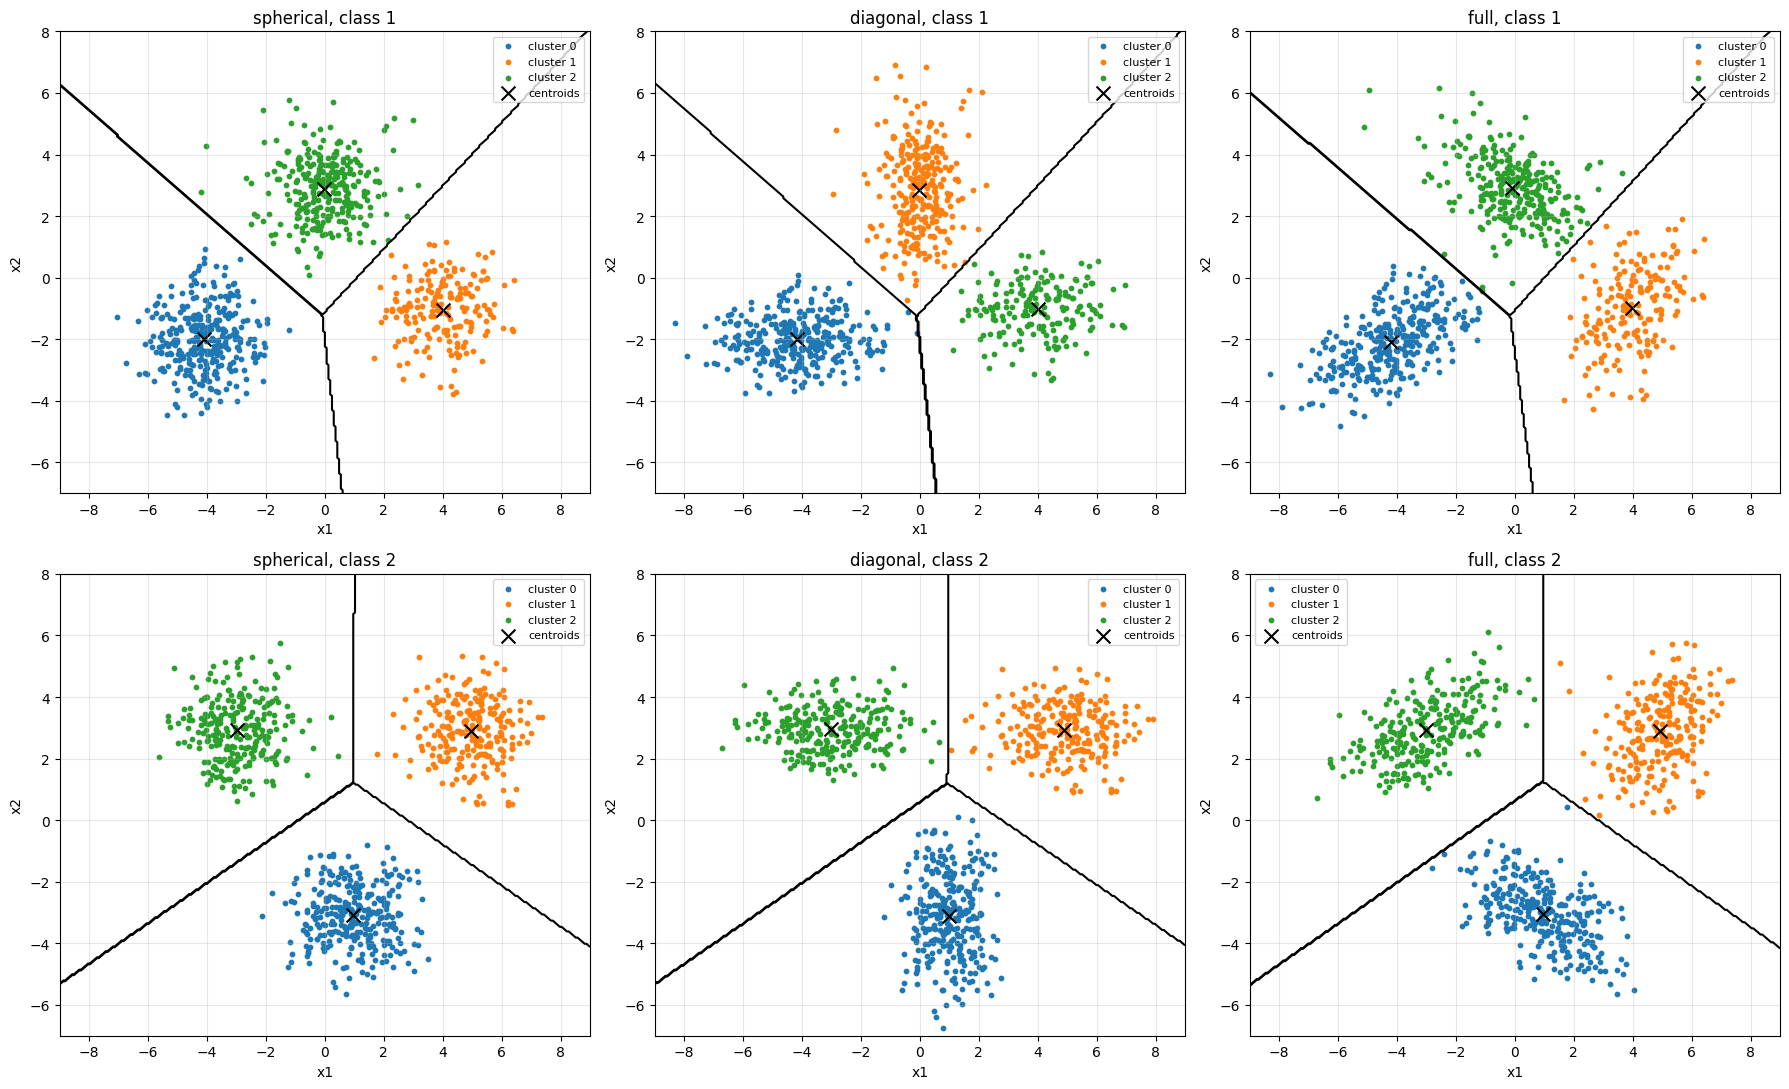

In [19]:
# CELL 9: clusters and boundaries (boundary = points equally close to two centroids)
cluster_colors = ["tab:blue", "tab:orange", "tab:green"]
xs = np.linspace(-9, 9, 300)
ys = np.linspace(-7, 8, 300)
xx, yy = np.meshgrid(xs, ys)
grid = np.stack([xx.ravel(), yy.ravel()], axis=1)

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for col, case in enumerate(TRAIN):
    for c in (0, 1):
        ax = axes[c, col]
        X = TRAIN[case][c]
        cent = CENTROIDS[case][c]
        d = ((grid[:, None, :] - cent[None, :, :]) ** 2).sum(axis=2)
        grid_labels = d.argmin(axis=1).reshape(xx.shape)
        for k in range(K):
            ax.scatter(X[LABELS[case][c] == k, 0], X[LABELS[case][c] == k, 1],
                       s=10, c=cluster_colors[k], label="cluster " + str(k))
        ax.scatter(cent[:, 0], cent[:, 1], c="k", marker="x", s=100, label="centroids")
        ax.contour(xx, yy, grid_labels, levels=[0.5, 1.5], colors="k")
        ax.set_title(case + ", class " + str(c + 1))
        ax.set_xlabel("x1")
        ax.set_ylabel("x2")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:

PRED = {}                       # PRED[case][true class] = predicted class of each test point
for case in TEST:
    PRED[case] = {}
    for c in (0, 1):
        X = TEST[case][c]
        distortion = []
        for cls in (0, 1):
            d = ((X[:, None, :] - CENTROIDS[case][cls][None, :, :]) ** 2).sum(axis=2)
            distortion.append(d.min(axis=1))
        distortion = np.stack(distortion, axis=1)
        PRED[case][c] = distortion.argmin(axis=1)

In [22]:
# CELL 11: accuracy
for case in PRED:
    correct0 = int(np.sum(PRED[case][0] == 0))
    correct1 = int(np.sum(PRED[case][1] == 1))
    total = len(PRED[case][0]) + len(PRED[case][1])
    print(case + ": class 0 " + str(correct0) + "/" + str(len(PRED[case][0])) +
          ", class 1 " + str(correct1) + "/" + str(len(PRED[case][1])) +
          ", overall " + str(round((correct0 + correct1) / total, 3)))

spherical: class 0 184/200, class 1 190/200, overall 0.935
diagonal: class 0 185/200, class 1 181/200, overall 0.915
full: class 0 177/200, class 1 185/200, overall 0.905
